# Harry Potter and the Philosopher’s Stone: character dialogue analysis

This notebook reads the supplied movie dialogue table, builds a character interaction network, compares centrality for villains and non-villains, computes lightweight linguistic features, and plots centrality against those features. It also provides a parallel workflow for the first book once book dialogue has been extracted into a table.

**Interaction definition:** each pair of different characters speaking in consecutive rows of the same chapter receives an undirected interaction edge. Repeated exchanges increase edge weight. This is a dialogue adjacency proxy, not a claim that every pair directly interacts in the story.


In [12]:
from pathlib import Path
import re
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

MOVIE_PATH = Path("../movie_data/hp1.csv")  
dialogue = pd.read_csv(MOVIE_PATH)
dialogue.head()


,movie,chapter,character,dialog
0,Harry Potter and the Philosopher's Stone,Doorstep Delivery,Albus Dumbledore,I should have known that you would be here...P...
1,Harry Potter and the Philosopher's Stone,Doorstep Delivery,Minerva McGonagall,"Good evening, Professor Dumbledore. Are the ru..."
2,Harry Potter and the Philosopher's Stone,Doorstep Delivery,Albus Dumbledore,"I'm afraid so, Professor. The good, and the bad."
3,Harry Potter and the Philosopher's Stone,Doorstep Delivery,Minerva McGonagall,And the boy?
4,Harry Potter and the Philosopher's Stone,Doorstep Delivery,Albus Dumbledore,Hagrid is bringing him.


## Prepare the dialogue table

Each row is one utterance. We preserve the full character roster, including speakers who do not form an edge under the consecutive-turn definition.

In [13]:
required = {"movie", "chapter", "character", "dialog"}
missing = required - set(dialogue.columns)
if missing: 
    raise ValueError(f"Missing expected columns: {sorted(missing)}")
dialogue = dialogue.dropna(subset=["character", "dialog"]).copy()
dialogue["character"] = dialogue["character"].astype(str).str.strip()
dialogue["dialog"] = dialogue["dialog"].astype(str)
dialogue["turn"] = dialogue.groupby("chapter", sort=False).cumcount()
print(f"{len(dialogue)} utterances; {dialogue['chapter'].nunique()} chapters; {dialogue['character'].nunique()} speakers")
dialogue[["chapter", "character", "dialog"]].head(10)


885 utterances; 34 chapters; 50 speakers


,chapter,character,dialog
0,Doorstep Delivery,Albus Dumbledore,I should have known that you would be here...P...
1,Doorstep Delivery,Minerva McGonagall,"Good evening, Professor Dumbledore. Are the ru..."
2,Doorstep Delivery,Albus Dumbledore,"I'm afraid so, Professor. The good, and the bad."
3,Doorstep Delivery,Minerva McGonagall,And the boy?
4,Doorstep Delivery,Albus Dumbledore,Hagrid is bringing him.
5,Doorstep Delivery,Minerva McGonagall,Do you think it wise to trust Hagrid with some...
6,Doorstep Delivery,Albus Dumbledore,"Ah, Professor, I would trust Hagrid with my life."
7,Doorstep Delivery,Rubeus Hagrid,"Professor Dumbledore, Sir. Professor McGonagall."
8,Doorstep Delivery,Albus Dumbledore,"No problems, I trust, Hagrid?"
9,Doorstep Delivery,Rubeus Hagrid,"No, sir. Little tyke fell asleep just as we we..."


## Build the movie interaction network

In [14]:
def interaction_graph(table):
    """Undirected weighted graph from adjacent, distinct speakers in each chapter."""
    graph = nx.Graph()
    speakers = table["character"].dropna().astype(str).str.strip().unique()
    graph.add_nodes_from(speakers)
    ordered = table.reset_index(drop=True)
    for _, scene in ordered.groupby("chapter", sort=False):
        names = scene["character"].astype(str).str.strip().tolist()
        for left, right in zip(names, names[1:]):
            if left != right:
                if graph.has_edge(left, right):
                    graph[left][right]["weight"] += 1
                else:
                    graph.add_edge(left, right, weight=1)
    return graph

movie_graph = interaction_graph(dialogue)
print(f"Nodes: {movie_graph.number_of_nodes()}, edges: {movie_graph.number_of_edges()}, components: {nx.number_connected_components(movie_graph)}")


Nodes: 50, edges: 144, components: 1


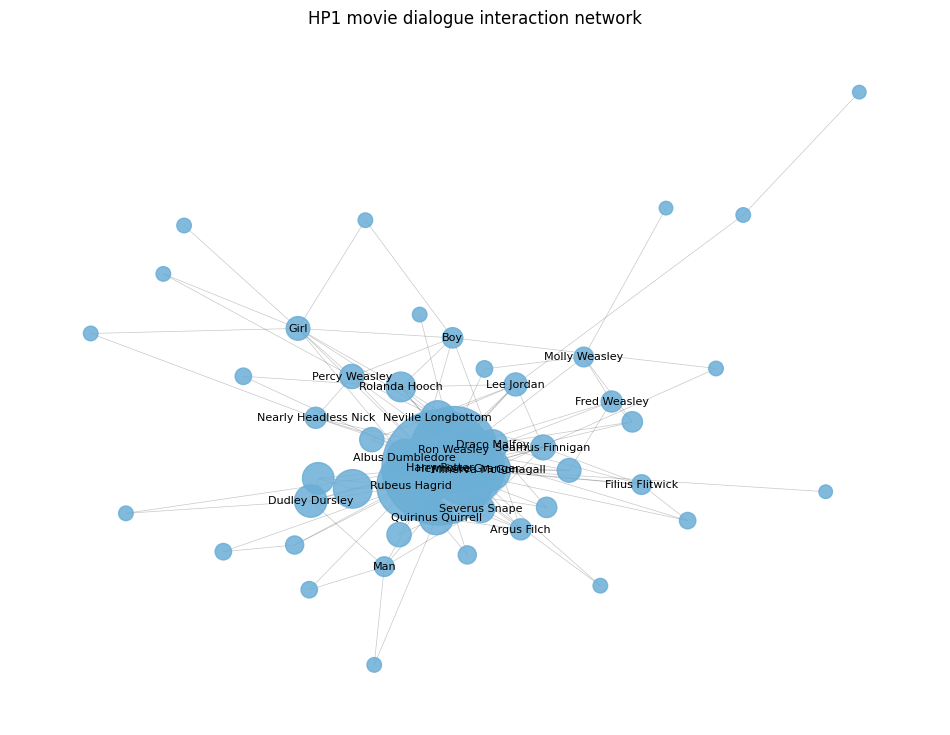

In [15]:
plt.figure(figsize=(12, 9))
pos = nx.spring_layout(movie_graph, seed=42, weight="weight")
node_sizes = [80 + 15 * movie_graph.degree(n, weight="weight") for n in movie_graph]
nx.draw_networkx_edges(movie_graph, pos, alpha=.22, width=.5)
nx.draw_networkx_nodes(movie_graph, pos, node_size=node_sizes, node_color="#6baed6", alpha=.85)
labels = {n: n for n in movie_graph if movie_graph.degree(n) >= 5}
nx.draw_networkx_labels(movie_graph, pos, labels=labels, font_size=8)
plt.title("HP1 movie dialogue interaction network")
plt.axis("off");


## Villains and centrality

Villain status is a hand-curated story label, not inferred from dialogue. This initial list marks Quirinus Quirrell and Voldemort as HP1 antagonists; edit it if your definition includes other characters. We report degree, weighted degree, betweenness, and eigenvector centrality. Centralities are calculated on the full graph.

In [16]:
VILLAINS = {"Quirinus Quirrell", "Voldemort"}  # editable, story-based labels
unknown = VILLAINS - set(movie_graph.nodes)
if unknown:
    print("Villain labels absent from this dialogue file:", sorted(unknown))

centralities = pd.DataFrame({
    "degree": dict(movie_graph.degree()),
    "weighted_degree": dict(movie_graph.degree(weight="weight")),
    "betweenness": nx.betweenness_centrality(movie_graph, normalized=True, weight=None),
    "eigenvector": nx.eigenvector_centrality(movie_graph, max_iter=2000, weight="weight"),
})
centralities["role"] = ["Villain" if name in VILLAINS else "Non-villain" for name in centralities.index]
centralities.sort_values("weighted_degree", ascending=False).head(15)


,degree,weighted_degree,betweenness,eigenvector,role
Harry Potter,33,454,0.491491,0.625349,Non-villain
Ron Weasley,18,251,0.102110,0.552362,Non-villain
Hermione Granger,16,186,0.077837,0.423294,Non-villain
Rubeus Hagrid,19,154,0.137430,0.315824,Non-villain
Minerva McGonagall,12,57,0.043151,0.068156,Non-villain
Vernon Dursley,4,46,0.000000,0.056772,Non-villain
Albus Dumbledore,7,39,0.007882,0.068248,Non-villain
Quirinus Quirrell,9,34,0.030305,0.035810,Villain
Neville Longbottom,10,34,0.021259,0.034496,Non-villain
Dudley Dursley,6,31,0.004615,0.026236,Non-villain


## Linguistic features by character

Features are descriptive counts and ratios from each character’s dialogue: utterances, total words, mean words per utterance, mean word length, question/exclamation rates, and a small first-person pronoun rate. Punctuation and tokenization are intentionally simple; these are not sentiment or personality measures.

In [17]:
WORD_RE = re.compile(r"\b[\w’'-]+\b", flags=re.UNICODE)
FIRST_PERSON = {"i", "me", "my", "mine", "we", "us", "our", "ours"}

def linguistic_features(table):
    rows = []
    for character, part in table.groupby("character", sort=True):
        utterances = part["dialog"].astype(str).tolist()
        tokens = [WORD_RE.findall(text.lower()) for text in utterances]
        all_tokens = [token for utterance in tokens for token in utterance]
        n_utterances = len(utterances)
        n_words = len(all_tokens)
        rows.append({
            "character": character,
            "utterances": n_utterances,
            "words": n_words,
            "mean_words_per_utterance": n_words / n_utterances if n_utterances else 0,
            "mean_word_length": sum(map(len, all_tokens)) / n_words if n_words else 0,
            "question_rate": sum("?" in text for text in utterances) / n_utterances if n_utterances else 0,
            "exclamation_rate": sum("!" in text for text in utterances) / n_utterances if n_utterances else 0,
            "first_person_rate": sum(token in FIRST_PERSON for token in all_tokens) / n_words if n_words else 0,
        })
    return pd.DataFrame(rows).set_index("character")

linguistics = linguistic_features(dialogue)
movie_analysis = centralities.join(linguistics).sort_values("weighted_degree", ascending=False)
movie_analysis.head(15)


,degree,weighted_degree,betweenness,eigenvector,role,utterances,words,mean_words_per_utterance,mean_word_length,question_rate,exclamation_rate,first_person_rate
Harry Potter,33,454,0.491491,0.625349,Non-villain,242,1723,7.119835,4.117818,0.371901,0.227273,0.057458
Ron Weasley,18,251,0.102110,0.552362,Non-villain,142,1077,7.584507,4.159703,0.253521,0.422535,0.046425
Hermione Granger,16,186,0.077837,0.423294,Non-villain,97,968,9.979381,4.367769,0.360825,0.268041,0.032025
Rubeus Hagrid,19,154,0.137430,0.315824,Non-villain,86,1445,16.802326,4.121799,0.302326,0.244186,0.030450
Minerva McGonagall,12,57,0.043151,0.068156,Non-villain,31,523,16.870968,4.397706,0.354839,0.064516,0.036329
Vernon Dursley,4,46,0.000000,0.056772,Non-villain,25,208,8.320000,3.923077,0.160000,0.680000,0.048077
Albus Dumbledore,7,39,0.007882,0.068248,Non-villain,24,729,30.375000,4.229081,0.166667,0.125000,0.045267
Quirinus Quirrell,9,34,0.030305,0.035810,Villain,17,242,14.235294,4.289256,0.411765,0.294118,0.061983
Neville Longbottom,10,34,0.021259,0.034496,Non-villain,18,108,6.000000,4.444444,0.166667,0.722222,0.046296
Dudley Dursley,6,31,0.004615,0.026236,Non-villain,17,86,5.058824,4.034884,0.235294,0.764706,0.046512


## Centrality versus linguistic features

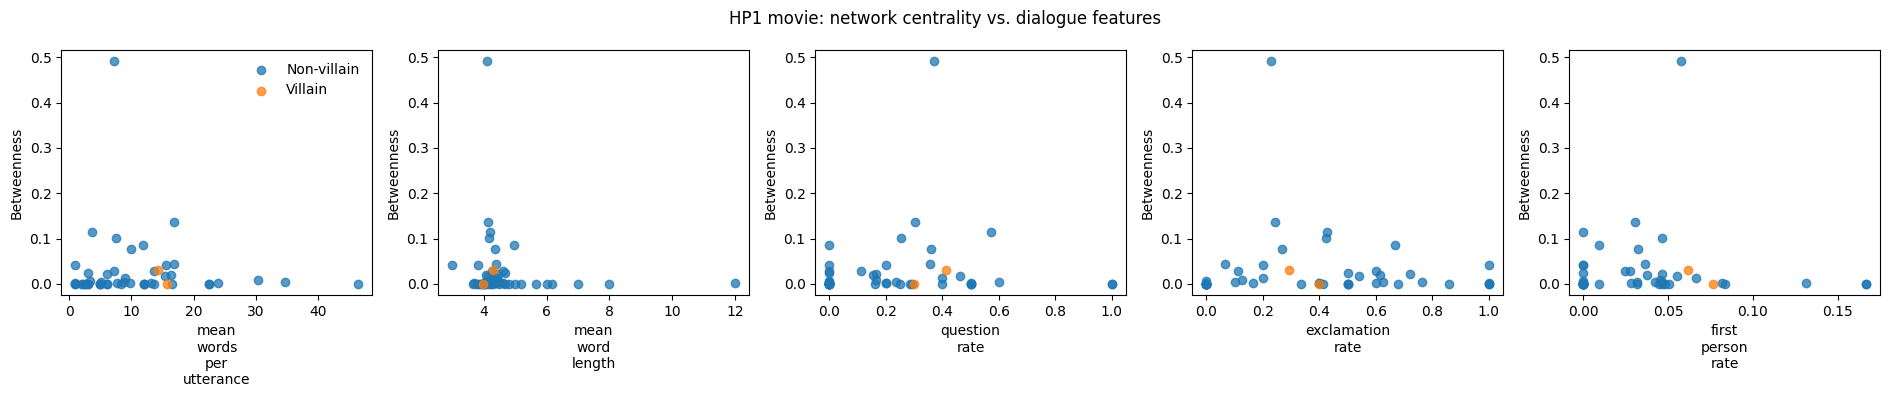

In [18]:
features_to_plot = ["mean_words_per_utterance", "mean_word_length", "question_rate", "exclamation_rate", "first_person_rate"]
fig, axes = plt.subplots(1, len(features_to_plot), figsize=(19, 4))
for ax, feature in zip(axes, features_to_plot):
    for role, subset in movie_analysis.groupby("role"):
        ax.scatter(subset[feature], subset["betweenness"], label=role, alpha=.75)
    ax.set_xlabel(feature.replace("_", "\n")); ax.set_ylabel("Betweenness")
axes[0].legend(frameon=False)
fig.suptitle("HP1 movie: network centrality vs. dialogue features")
plt.tight_layout()


## First book: repeat after extracting dialogue

No book dialogue table is included in this project, so the book analysis cannot be computed from the movie script. Once dialogue has been extracted into a CSV with `chapter`, `character`, and `dialog` columns, place it at `../book_data/hp1_dialogue.csv` (or change the path below). The extraction should identify speaker turns and preserve chapter order. Then this cell reuses the same network and feature definitions for an apples-to-apples comparison.

In [19]:
BOOK_PATH = Path("../book_data/hp1_dialogue.csv")
if BOOK_PATH.exists():
    book_dialogue = pd.read_csv(BOOK_PATH)
    book_required = {"chapter", "character", "dialog"}
    book_missing = book_required - set(book_dialogue.columns)
    if book_missing:
        raise ValueError(f"Book dialogue is missing columns: {sorted(book_missing)}")
    book_dialogue = book_dialogue.dropna(subset=["chapter", "character", "dialog"]).copy()
    book_graph = interaction_graph(book_dialogue)
    book_centralities = pd.DataFrame({
        "degree": dict(book_graph.degree()),
        "weighted_degree": dict(book_graph.degree(weight="weight")),
        "betweenness": nx.betweenness_centrality(book_graph, normalized=True, weight=None),
        "eigenvector": nx.eigenvector_centrality(book_graph, max_iter=2000, weight="weight"),
    })
    book_centralities["role"] = ["Villain" if n in VILLAINS else "Non-villain" for n in book_centralities.index]
    book_analysis = book_centralities.join(linguistic_features(book_dialogue))
    display(book_analysis.sort_values("weighted_degree", ascending=False).head(15))
else:
    print(f"Book dialogue not found at {BOOK_PATH}. Extract dialogue first, then rerun this cell.")


,degree,weighted_degree,betweenness,eigenvector,role,utterances,words,mean_words_per_utterance,mean_word_length,question_rate,exclamation_rate,first_person_rate
Unknown,11,50,1.0,0.707105,Non-villain,2273,22983,10.111307,4.168342,0.252970,0.144743,0.045512
Professor McGonagall,1,22,0.0,0.645944,Non-villain,11,58,5.272727,4.189655,0.181818,0.090909,0.051724
Firenze,1,6,0.0,0.176167,Non-villain,3,22,7.333333,3.909091,0.333333,0.000000,0.000000
Griphook,1,4,0.0,0.117444,Non-villain,4,28,7.000000,4.428571,0.000000,0.000000,0.000000
Professor Flitwick,1,4,0.0,0.117444,Non-villain,2,7,3.500000,3.857143,0.000000,0.500000,0.000000
Dedalus Diggle,1,2,0.0,0.058722,Non-villain,1,2,2.000000,5.500000,0.000000,1.000000,0.000000
Ollivander,1,2,0.0,0.058722,Non-villain,1,15,15.000000,4.133333,0.000000,1.000000,0.000000
Nearly Headless Nick,1,2,0.0,0.058722,Non-villain,1,3,3.000000,4.666667,0.000000,0.000000,0.000000
Madam Hooch,1,2,0.0,0.058722,Non-villain,1,13,13.000000,3.692308,0.000000,0.000000,0.153846
Hermione Granger,1,2,0.0,0.058722,Non-villain,1,1,1.000000,2.000000,0.000000,1.000000,0.000000


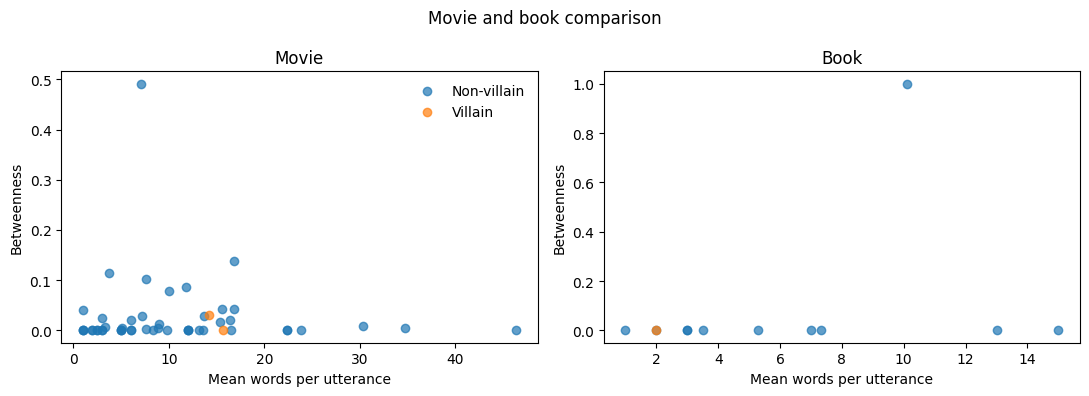

In [20]:
if BOOK_PATH.exists():
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    for ax, data, title in [(axes[0], movie_analysis, "Movie"), (axes[1], book_analysis, "Book")]:
        for role, subset in data.groupby("role"):
            ax.scatter(subset["mean_words_per_utterance"], subset["betweenness"], label=role, alpha=.7)
        ax.set(title=title, xlabel="Mean words per utterance", ylabel="Betweenness")
    axes[0].legend(frameon=False)
    fig.suptitle("Movie and book comparison")
    plt.tight_layout()
